In [4]:
print("Libraries imported successfully!")

Libraries imported successfully!


In [5]:

# Import required libraries

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.datasets import fetch_openml
from sklearn.model_selection import train_test_split
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import StandardScaler, OneHotEncoder
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import accuracy_score, classification_report
from sklearn.feature_selection import mutual_info_classif

print("All libraries imported successfully!")


All libraries imported successfully!


In [6]:


dataset = fetch_openml(
    "adult",
    version=2,
    as_frame=True
)

X = dataset.data.copy()
y = dataset.target.copy()

X = X.replace("?", np.nan)

print("Dataset loaded successfully!")
print("Dataset shape:", X.shape)


display(X.head())


Dataset loaded successfully!
Dataset shape: (48842, 14)


,age,workclass,fnlwgt,education,education-num,marital-status,occupation,relationship,race,sex,capital-gain,capital-loss,hours-per-week,native-country
0,25,Private,226802,11th,7,Never-married,Machine-op-inspct,Own-child,Black,Male,0,0,40,United-States
1,38,Private,89814,HS-grad,9,Married-civ-spouse,Farming-fishing,Husband,White,Male,0,0,50,United-States
2,28,Local-gov,336951,Assoc-acdm,12,Married-civ-spouse,Protective-serv,Husband,White,Male,0,0,40,United-States
3,44,Private,160323,Some-college,10,Married-civ-spouse,Machine-op-inspct,Husband,Black,Male,7688,0,40,United-States
4,18,NaN,103497,Some-college,10,Never-married,NaN,Own-child,White,Female,0,0,30,United-States


In [7]:



y = y.astype(str).str.strip().str.rstrip(".")

y = y.map({
    "<=50K": 0,
    ">50K": 1
})

print("Target variable prepared!")
print("\nTarget distribution:")
print(y.value_counts())

print("\nTarget classes:")
print("0 = Income <= 50K")
print("1 = Income > 50K")


Target variable prepared!

Target distribution:
class
0    37155
1    11687
Name: count, dtype: int64

Target classes:
0 = Income <= 50K
1 = Income > 50K


In [8]:


X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.20,
    random_state=42,
    stratify=y
)

print("Train-test split completed!")

print("Training features:", X_train.shape)
print("Testing features:", X_test.shape)

print("Training target:", y_train.shape)
print("Testing target:", y_test.shape)


Train-test split completed!
Training features: (39073, 14)
Testing features: (9769, 14)
Training target: (39073,)
Testing target: (9769,)


In [9]:

numeric_features = X_train.select_dtypes(include=["number"]).columns.tolist()

categorical_features = X_train.select_dtypes(exclude=["number"]).columns.tolist()

print("Numerical columns:")
print(numeric_features)

print("\nCategorical columns:")
print(categorical_features)

Numerical columns:
['age', 'fnlwgt', 'education-num', 'capital-gain', 'capital-loss', 'hours-per-week']

Categorical columns:
['workclass', 'education', 'marital-status', 'occupation', 'relationship', 'race', 'sex', 'native-country']


## Correlation Analysis

The following heatmap shows correlations between numerical features in the training dataset. Using only the training data keeps the analysis separate from the held-out test set.

In [ ]:
# Correlation analysis on numerical training features only

correlation_matrix = X_train[numeric_features].corr()

plt.figure(figsize=(12, 8))
sns.heatmap(
    correlation_matrix,
    annot=True,
    cmap="coolwarm",
    fmt=".2f",
    linewidths=0.5
)

plt.title("Correlation Heatmap of Numerical Training Features")
plt.tight_layout()
plt.show()

In [10]:


numeric_pipeline = Pipeline(steps=[
    ("imputer", SimpleImputer(strategy="median")),
    ("scaler", StandardScaler())
])



categorical_pipeline = Pipeline(steps=[
    ("imputer", SimpleImputer(strategy="most_frequent")),
    ("encoder", OneHotEncoder(handle_unknown="ignore"))
])

print("Numerical and categorical pipelines created successfully!")

Numerical and categorical pipelines created successfully!


In [11]:


preprocessor = ColumnTransformer(
    transformers=[
        ("num", numeric_pipeline, numeric_features),
        ("cat", categorical_pipeline, categorical_features)
    ]
)

print("ColumnTransformer created successfully!")

ColumnTransformer created successfully!


In [12]:


model = Pipeline(steps=[
    ("preprocessor", preprocessor),
    ("classifier", LogisticRegression(max_iter=1000))
])

print("Complete machine learning pipeline created successfully!")

Complete machine learning pipeline created successfully!


In [13]:


model.fit(X_train, y_train)

print("Model training completed successfully!")

Model training completed successfully!


In [14]:


y_pred = model.predict(X_test)

print("Predictions completed successfully!")

Predictions completed successfully!


In [16]:
from sklearn.metrics import confusion_matrix

print("Confusion Matrix:")
print(confusion_matrix(y_test, y_pred))

Confusion Matrix:
[[6951  480]
 [ 962 1376]]


In [17]:


X_train_transformed = model.named_steps["preprocessor"].transform(X_train)

feature_names = model.named_steps["preprocessor"].get_feature_names_out()

mi_scores = mutual_info_classif(
    X_train_transformed,
    y_train,
    random_state=42
)

feature_importance = pd.DataFrame({
    "Feature": feature_names,
    "Importance": mi_scores
})

feature_importance = feature_importance.sort_values(
    by="Importance",
    ascending=False
)

print("Top 15 Important Features:")
display(feature_importance.head(15))

/usr/local/lib/python3.13/dist-packages/sklearn/metrics/cluster/_supervised.py:59: UserWarning: Clustering metrics expects discrete values but received continuous values for label, and binary values for target
  warnings.warn(msg, UserWarning)
/usr/local/lib/python3.13/dist-packages/sklearn/metrics/cluster/_supervised.py:59: UserWarning: Clustering metrics expects discrete values but received continuous values for label, and binary values for target
  warnings.warn(msg, UserWarning)
/usr/local/lib/python3.13/dist-packages/sklearn/metrics/cluster/_supervised.py:59: UserWarning: Clustering metrics expects discrete values but received continuous values for label, and binary values for target
  warnings.warn(msg, UserWarning)
/usr/local/lib/python3.13/dist-packages/sklearn/metrics/cluster/_supervised.py:59: UserWarning: Clustering metrics expects discrete values but received continuous values for label, and binary values for target
  warnings.warn(msg, UserWarning)
/usr/local/lib/python3.1

Top 15 Important Features:


,Feature,Importance
1,num__fnlwgt,0.377372
32,cat__marital-status_Married-civ-spouse,0.107539
51,cat__relationship_Husband,0.082842
3,num__capital-gain,0.081788
0,num__age,0.067948
2,num__education-num,0.063378
34,cat__marital-status_Never-married,0.063306
5,num__hours-per-week,0.041373
4,num__capital-loss,0.038161
54,cat__relationship_Own-child,0.036417


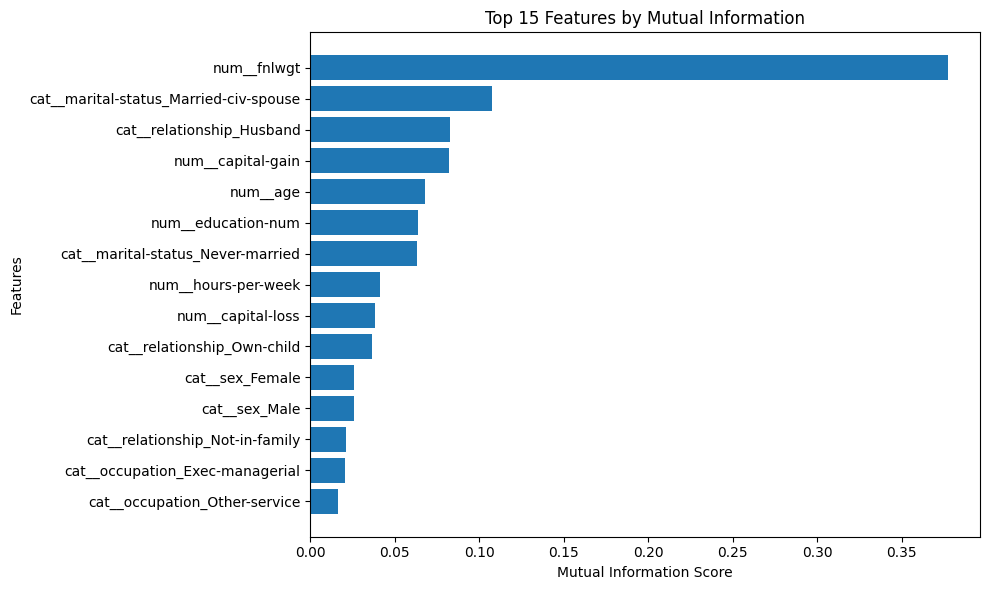

In [18]:
plt.figure(figsize=(10, 6))

top_features = feature_importance.head(15)

plt.barh(
    top_features["Feature"],
    top_features["Importance"]
)

plt.xlabel("Mutual Information Score")
plt.ylabel("Features")
plt.title("Top 15 Features by Mutual Information")

plt.gca().invert_yaxis()
plt.tight_layout()
plt.show()

## Conclusion

A reusable machine learning preprocessing pipeline was developed using the Adult Census Income dataset. Numerical features were imputed and scaled, while categorical features were imputed and one-hot encoded using a Scikit-learn `ColumnTransformer`. The data was split into training and testing sets before fitting the preprocessing pipeline to avoid data leakage. A Logistic Regression classifier achieved **85.24% test accuracy** in the reported run. Mutual Information was used to rank informative transformed features, and a correlation heatmap was created for numerical training features.